# EDA02: Hotel Operations Analysis (Elite Hotels International)

**Objective:** Load the `hotel_bookings.csv` dataset and inspect its dimensions, data types, missing values, and duplicate entries before cleaning.

In [81]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset (one folder up from notebook/)
df = pd.read_csv("../data/hotel_bookings.csv")

print(f"Raw Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head())

# Check missing values and duplicates
print("\nMissing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])
print(f"\nDuplicate Rows: {df.duplicated().sum()}")

Raw Dataset Shape: 119390 rows, 32 columns


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Missing Values:
children         4
country        488
agent        16340
company     112593
dtype: int64

Duplicate Rows: 31994


## Data Cleaning & Preprocessing

**Steps:**
1. Fill missing `children` values with `0` and convert to integer.
2. Fill missing `country` values with `'Unknown'`.
3. Keep `agent` and `company` `NaN` values intact so non-null counts accurately reflect bookings made through travel agents or companies.
4. Convert `reservation_status_date` to datetime format.
5. Check and remove duplicate rows.

In [82]:
# 1. Handle missing values
df['children'] = df['children'].fillna(0).astype(int)
df['country'] = df['country'].fillna('Unknown')

# 2. Convert date column to datetime
df['reservation_status_date'] = pd.to_datetime(df['reservation_status_date'])

# 3. Remove duplicate rows
df = df.drop_duplicates().reset_index(drop=True)

print(f"Cleaned Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nRemaining Missing Values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Cleaned Dataset Shape: 87396 rows, 32 columns

Remaining Missing Values:
agent      12193
company    82137
dtype: int64


**Conclusion:** After filling missing values in `children` (with `0`) and `country` (with `'Unknown'`), converting `reservation_status_date` to datetime format, and removing `31,994` duplicate rows, the cleaned dataset contains **87,396 unique bookings and 32 columns**. Missing values in `agent` (12,193) and `company` (82,137) are intentionally retained so non-null counts accurately identify travel agency and corporate bookings.

## Part 1: Basic-Level Questions

### Basic Question 1: What is the average lead time for bookings?

**Objective:** Calculate the mean (and summary statistics) of the `lead_time` column to understand how many days in advance guests typically book their stays.

In [83]:
# Calculate average lead time and summary statistics
avg_lead_time = df['lead_time'].mean()
median_lead_time = df['lead_time'].median()

print(f"Average Lead Time: {avg_lead_time:.2f} days")
print(f"Median Lead Time: {median_lead_time:.2f} days")

# Full summary statistics for lead_time
display(df['lead_time'].describe().round(2).to_frame(name='Lead_Time_Days'))

Average Lead Time: 79.89 days
Median Lead Time: 49.00 days


,Lead_Time_Days
count,87396.00
mean,79.89
std,86.05
min,0.00
25%,11.00
50%,49.00
75%,125.00
max,737.00


**Conclusion:** Guests book their stays an average of **79.89 days (~2.6 months)** in advance, with a **median lead time of 49.00 days (~7 weeks)**. While **25%** of bookings are made within **11 days** of arrival (last-minute travelers), early-bird bookings extending up to **737 days** pull the overall average noticeably higher than the median.

### Basic Question 2: What is the distribution of bookings by hotel type?

**Objective:** Count the number and percentage share of bookings for each hotel type (`City Hotel` vs. `Resort Hotel`) and visualize the distribution with a bar chart.

,Booking_Count,Percentage (%)
hotel,,
City Hotel,53428,61.13
Resort Hotel,33968,38.87


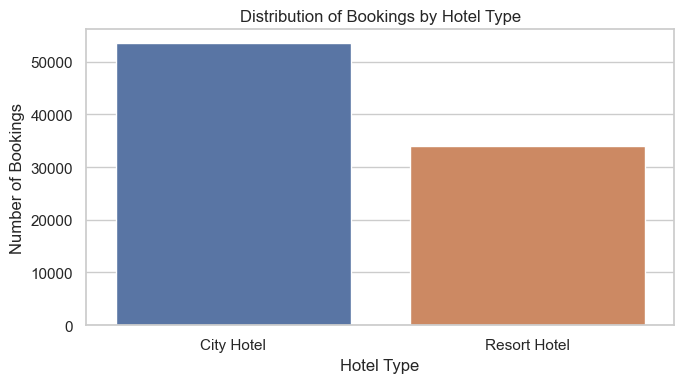

In [84]:
# Count bookings and calculate percentage share by hotel type
hotel_counts = df['hotel'].value_counts()
hotel_pct = (df['hotel'].value_counts(normalize=True) * 100).round(2)

hotel_dist = pd.DataFrame({
    'Booking_Count': hotel_counts,
    'Percentage (%)': hotel_pct
})
display(hotel_dist)

# Bar chart of bookings by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(x=hotel_dist.index, y=hotel_dist['Booking_Count'], hue=hotel_dist.index, legend=False)
plt.title('Distribution of Bookings by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** accounts for the majority of reservations with **53,428 bookings (61.13%)**, compared to **33,968 bookings (38.87%)** for **Resort Hotel**—nearly a **1.6-to-1 ratio** favoring urban hotel properties across the dataset.

### Basic Question 3: How many bookings were canceled?

**Objective:** Sum the values in the `is_canceled` column (`1` = Canceled, `0` = Not Canceled) to calculate total cancellations and the overall cancellation rate.

In [85]:
# Count total canceled and non-canceled bookings
total_canceled = df['is_canceled'].sum()
total_bookings = len(df)
cancellation_rate = (total_canceled / total_bookings) * 100

print(f"Total Canceled Bookings: {total_canceled}")
print(f"Total Non-Canceled Bookings: {total_bookings - total_canceled}")
print(f"Overall Cancellation Rate: {cancellation_rate:.2f}%")

# Summary breakdown table
cancel_summary = pd.DataFrame({
    'Status': ['Not Canceled (0)', 'Canceled (1)'],
    'Count': [total_bookings - total_canceled, total_canceled],
    'Percentage (%)': [round(100 - cancellation_rate, 2), round(cancellation_rate, 2)]
})
display(cancel_summary)

Total Canceled Bookings: 24025
Total Non-Canceled Bookings: 63371
Overall Cancellation Rate: 27.49%


,Status,Count,Percentage (%)
0,Not Canceled (0),63371,72.51
1,Canceled (1),24025,27.49


**Conclusion:** Out of **87,396 unique bookings**, a total of **24,025 bookings (27.49%)** were canceled, while **63,371 bookings (72.51%)** were not canceled—meaning more than **1 in 4 reservations** results in a cancellation.

### Basic Question 4: What is the most common arrival month for bookings?

**Objective:** Find the mode and monthly booking counts of `arrival_date_month` to identify peak arrival seasons.

Most Common Arrival Month: August


,Booking_Count
arrival_date_month,
January,4693
February,6098
March,7513
April,7908
May,8355
June,7765
July,10057
August,11257
September,6690


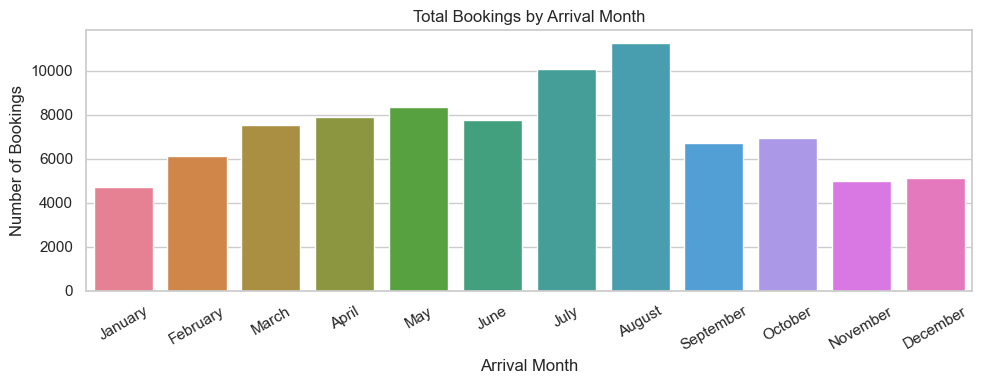

In [86]:
# Find the most common arrival month (mode) and full monthly counts
most_common_month = df['arrival_date_month'].mode()[0]
print(f"Most Common Arrival Month: {most_common_month}")

# Order months chronologically from January to December
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]
monthly_arrivals = df['arrival_date_month'].value_counts().reindex(month_order)
display(monthly_arrivals.to_frame(name='Booking_Count'))

# Plot bookings by arrival month
plt.figure(figsize=(10, 4))
sns.barplot(x=monthly_arrivals.index, y=monthly_arrivals.values, hue=monthly_arrivals.index, legend=False)
plt.title('Total Bookings by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Number of Bookings')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusion:** **August** is the most common arrival month with **11,257 bookings (12.88% of all arrivals)**, followed closely by **July (10,057 bookings)**—highlighting a clear peak summer travel window. By contrast, winter months experience the lowest demand, dipping to **4,693 bookings in January** and **4,995 in November**.

### Basic Question 5: What is the average number of special requests per booking?

**Objective:** Calculate the mean and distribution of `total_of_special_requests` to understand guest service expectations across bookings.

In [87]:
# Calculate average number of special requests per booking
avg_special_requests = df['total_of_special_requests'].mean()
print(f"Average Special Requests per Booking: {avg_special_requests:.2f}")

# Distribution of special requests per booking
requests_dist = pd.DataFrame({
    'Booking_Count': df['total_of_special_requests'].value_counts().sort_index(),
    'Percentage (%)': (df['total_of_special_requests'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(requests_dist)

Average Special Requests per Booking: 0.70


,Booking_Count,Percentage (%)
total_of_special_requests,,
0,43894,50.22
1,29017,33.20
2,11812,13.52
3,2317,2.65
4,320,0.37
5,36,0.04


**Conclusion:** Guests submit an average of **0.70 special requests per booking**. Just over half of all reservations (**50.22%**, 43,894 bookings) include **no special requests**, while **33.20%** (29,017 bookings) include **1 request** and **16.58%** include **2 to 5 requests**—meaning nearly half of all arriving guests require at least one personalized accommodation or service arrangement.

### Basic Question 6: Which country has the highest number of bookings?

**Objective:** Count the bookings by `country` to identify the top country of origin and the major guest demographics.

Country with Highest Number of Bookings: PRT (27453 bookings)


,Booking_Count,Percentage (%)
country,,
PRT,27453,31.41
GBR,10433,11.94
FRA,8837,10.11
ESP,7252,8.30
DEU,5387,6.16
ITA,3066,3.51
IRL,3016,3.45
BEL,2081,2.38
BRA,1995,2.28


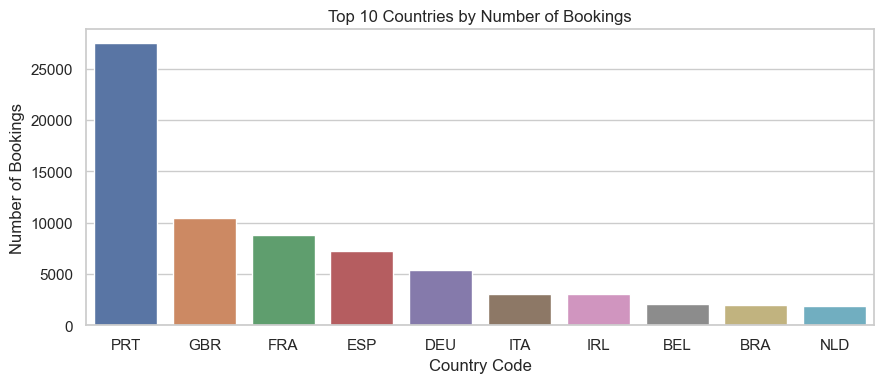

In [88]:
# Identify the top country and top 10 countries by booking count
top_country = df['country'].value_counts().index[0]
top_country_count = df['country'].value_counts().iloc[0]
print(f"Country with Highest Number of Bookings: {top_country} ({top_country_count} bookings)")

# Top 10 countries table with booking count and percentage share
top_10_countries = pd.DataFrame({
    'Booking_Count': df['country'].value_counts().head(10),
    'Percentage (%)': (df['country'].value_counts(normalize=True).head(10) * 100).round(2)
})
display(top_10_countries)

# Bar chart of Top 10 countries
plt.figure(figsize=(9, 4))
sns.barplot(x=top_10_countries.index, y=top_10_countries['Booking_Count'], hue=top_10_countries.index, legend=False)
plt.title('Top 10 Countries by Number of Bookings')
plt.xlabel('Country Code')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **Portugal (`PRT`)** generates the highest volume of reservations with **27,453 bookings (31.41% of all bookings)**, followed by the **United Kingdom (`GBR`, 10,433 bookings, 11.94%)**, **France (`FRA`, 8,837, 10.11%)**, **Spain (`ESP`, 7,252, 8.30%)**, and **Germany (`DEU`, 5,387, 6.16%)**. Together, these top 5 Western European countries represent **67.92%** of total guest demand.

### Basic Question 7: What is the average daily rate (ADR) for each hotel type?

**Objective:** Group the dataset by `hotel` and calculate the mean, median, and standard deviation of `adr` to compare daily room rate performance between `City Hotel` and `Resort Hotel`.

,Booking_Count,Mean_ADR,Median_ADR,Std_Dev
hotel,,,,
City Hotel,53428,110.99,105.3,48.06
Resort Hotel,33968,99.03,79.5,63.77


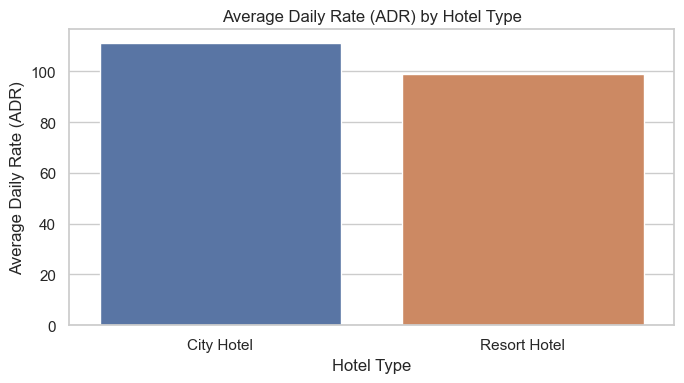

In [89]:
# Calculate ADR summary statistics by hotel type
adr_by_hotel = df.groupby('hotel')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median',
    Std_Dev='std'
).round(2)

display(adr_by_hotel)

# Bar chart comparing Mean ADR by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(x=adr_by_hotel.index, y=adr_by_hotel['Mean_ADR'], hue=adr_by_hotel.index, legend=False)
plt.title('Average Daily Rate (ADR) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Average Daily Rate (ADR)')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** achieves a higher Average Daily Rate (ADR) of **110.99** (median: **105.30**) compared to **99.03** (median: **79.50**) for **Resort Hotel**—a difference of **11.96 per night**. At the same time, **Resort Hotel** shows much wider rate variability (standard deviation of **63.77** vs. **48.06** for City Hotel), reflecting sharper seasonal price swings between off-peak winter months and peak summer resort demand.

### Basic Question 8: What percentage of guests required car parking spaces?

**Objective:** Calculate the number and percentage of bookings where `required_car_parking_spaces > 0` to assess guest parking demand.


In [90]:
# Calculate bookings requiring at least one car parking space
parking_required = (df['required_car_parking_spaces'] > 0).sum()
total_bookings = len(df)
parking_pct = (parking_required / total_bookings) * 100

print(f"Bookings Requiring Car Parking: {parking_required} out of {total_bookings}")
print(f"Percentage of Guests Requiring Parking: {parking_pct:.2f}%")

# Breakdown by number of parking spaces requested
parking_breakdown = pd.DataFrame({
    'Booking_Count': df['required_car_parking_spaces'].value_counts().sort_index(),
    'Percentage (%)': (df['required_car_parking_spaces'].value_counts(normalize=True).sort_index() * 100).round(2)
})
display(parking_breakdown)

Bookings Requiring Car Parking: 7313 out of 87396
Percentage of Guests Requiring Parking: 8.37%


,Booking_Count,Percentage (%)
required_car_parking_spaces,,
0,80083,91.63
1,7280,8.33
2,28,0.03
3,3,0.00
8,2,0.00


**Conclusion:** Only **8.37% of guests (7,313 out of 87,396 bookings)** required car parking spaces, while the remaining **91.63% (80,083 bookings)** required none. Nearly all parking demand comes from single-vehicle guests (**7,280 bookings, 8.33%**), indicating that current parking infrastructure needs to accommodate roughly **1 in every 12 reservations** rather than the full guest base.

### Basic Question 9: What is the average stay duration in week nights and weekend nights?

**Objective:** Calculate the mean and summary statistics of `stays_in_week_nights` and `stays_in_weekend_nights` (along with total stay duration) to understand typical guest stay lengths.

In [91]:
# Calculate average stay duration in week nights and weekend nights
avg_week_nights = df['stays_in_week_nights'].mean()
avg_weekend_nights = df['stays_in_weekend_nights'].mean()
avg_total_nights = (df['stays_in_week_nights'] + df['stays_in_weekend_nights']).mean()

print(f"Average Week Nights Stayed: {avg_week_nights:.2f} nights")
print(f"Average Weekend Nights Stayed: {avg_weekend_nights:.2f} nights")
print(f"Average Total Stay Duration: {avg_total_nights:.2f} nights")

# Summary statistics table
stay_summary = df[['stays_in_week_nights', 'stays_in_weekend_nights']].describe().round(2)
display(stay_summary)

Average Week Nights Stayed: 2.63 nights
Average Weekend Nights Stayed: 1.01 nights
Average Total Stay Duration: 3.63 nights


,stays_in_week_nights,stays_in_weekend_nights
count,87396.00,87396.00
mean,2.63,1.01
std,2.05,1.03
min,0.00,0.00
25%,1.00,0.00
50%,2.00,1.00
75%,4.00,2.00
max,50.00,19.00


**Conclusion:** Guests stay an average of **2.63 week nights** (median: **2.00**) and **1.01 weekend nights** (median: **1.00**), resulting in an overall average stay duration of **3.63 nights**. Because **75%** of bookings span **4 or fewer week nights** and **2 or fewer weekend nights**, the majority of hotel demand consists of short 3-to-4-night leisure or business trips rather than extended stays.

### Basic Question 10: How many bookings were made through travel agents?

**Objective:** Count the non-null values in the `agent` column to determine how many bookings were facilitated by travel agents versus direct/non-agent bookings.

In [92]:
# Count bookings made through travel agents (non-null values in 'agent')
agent_bookings = df['agent'].notnull().sum()
non_agent_bookings = df['agent'].isnull().sum()
total_bookings = len(df)
agent_pct = (agent_bookings / total_bookings) * 100

print(f"Bookings Made Through Travel Agents: {agent_bookings} out of {total_bookings}")
print(f"Percentage of Agent Bookings: {agent_pct:.2f}%")

# Breakdown table
agent_summary = pd.DataFrame({
    'Booking_Channel_Type': ['Travel Agent (agent present)', 'Direct / Non-Agent (agent missing)'],
    'Booking_Count': [agent_bookings, non_agent_bookings],
    'Percentage (%)': [round(agent_pct, 2), round(100 - agent_pct, 2)]
})
display(agent_summary)

Bookings Made Through Travel Agents: 75203 out of 87396
Percentage of Agent Bookings: 86.05%


,Booking_Channel_Type,Booking_Count,Percentage (%)
0,Travel Agent (agent present),75203,86.05
1,Direct / Non-Agent (agent missing),12193,13.95


**Conclusion:** A large majority of reservations—**75,203 out of 87,396 bookings (86.05%)**—were made through **travel agents**, whereas only **12,193 bookings (13.95%)** came through direct or non-agent channels. This heavy reliance on third-party travel agencies highlights the importance of maintaining strong agency partnerships while also building direct-booking incentives to reduce commission costs.

## Part 2: Medium-Level Questions

### Medium Question 1: What is the cancellation rate for each hotel type?

**Objective:** Group the dataset by `hotel` and calculate the total bookings, canceled bookings, and average cancellation rate (`is_canceled` mean) for `City Hotel` versus `Resort Hotel`.

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
hotel,,,
City Hotel,53428,16049,30.04
Resort Hotel,33968,7976,23.48


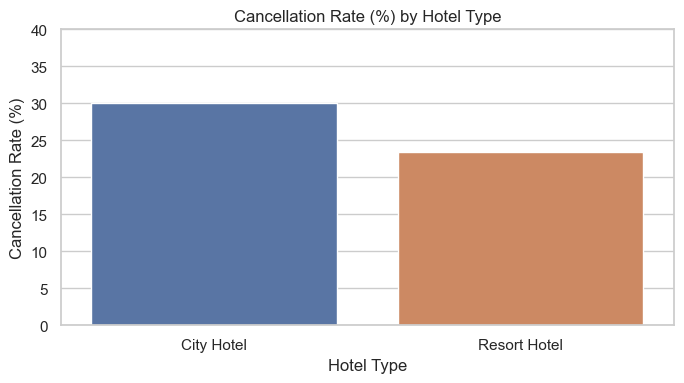

In [93]:
# Group by hotel type and calculate total bookings, canceled count, and cancellation rate (%)
cancel_by_hotel = df.groupby('hotel')['is_canceled'].agg(
    Total_Bookings='count',
    Canceled_Bookings='sum',
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
)

display(cancel_by_hotel)

# Bar chart of cancellation rate by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(
    x=cancel_by_hotel.index,
    y=cancel_by_hotel['Cancellation_Rate'],
    hue=cancel_by_hotel.index,
    legend=False
)
plt.title('Cancellation Rate (%) by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Cancellation Rate (%)')
plt.ylim(0, 40)
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** experiences a substantially higher cancellation rate of **30.04%** (**16,049** canceled out of **53,428** bookings) compared to **23.48%** (**7,976** canceled out of **33,968** bookings) for **Resort Hotel**—a **6.56 percentage-point gap**. City Hotel properties therefore require stricter deposit policies, cancellation deadlines, or targeted overbooking buffers to protect room occupancy.

### Medium Question 2: What is the average ADR per market segment?

**Objective:** Group the dataset by `market_segment` and calculate the booking count, mean ADR, and median ADR to compare daily rate performance across customer segments.

,Booking_Count,Mean_ADR,Median_ADR
market_segment,,,
Online TA,51618,118.17,110.70
Direct,11804,116.58,106.60
Aviation,227,100.17,95.00
Offline TA/TO,13889,81.76,79.05
Groups,4942,74.86,68.00
Corporate,4212,68.15,65.00
Undefined,2,15.00,15.00
Complementary,702,3.05,0.00


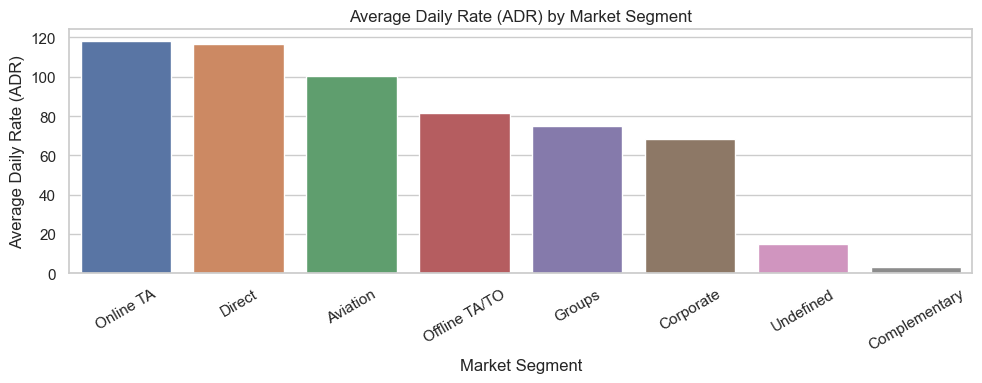

In [94]:
# Calculate average and median ADR per market segment
adr_by_segment = df.groupby('market_segment')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median'
).round(2).sort_values(by='Mean_ADR', ascending=False)

display(adr_by_segment)

# Bar chart of Mean ADR by market segment
plt.figure(figsize=(10, 4))
sns.barplot(
    x=adr_by_segment.index,
    y=adr_by_segment['Mean_ADR'],
    hue=adr_by_segment.index,
    legend=False
)
plt.title('Average Daily Rate (ADR) by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Average Daily Rate (ADR)')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusion:** **Online TA** generates the highest Average Daily Rate at **118.17** (median: **110.70**) across **51,618 bookings**, followed closely by **Direct** bookings at **116.58** (median: **106.60**). By contrast, bulk and negotiated channels such as **Offline TA/TO (81.76)**, **Groups (74.86)**, and **Corporate (68.15)** command substantially lower daily rates—showing that **Direct** bookings deliver nearly the same high nightly revenue as Online TAs without third-party commission fees.

### Medium Question 3: What is the relationship between lead time and cancellation rate?

**Objective:** Explore the correlation between `lead_time` and `is_canceled` using a scatter plot and summary statistics to see whether bookings made further in advance are more likely to be canceled.

Correlation between Lead Time and Cancellation: 0.1848


,Booking_Count,Mean_Lead_Time,Median_Lead_Time
is_canceled,,,
0,63371,70.10,38.0
1,24025,105.72,80.0


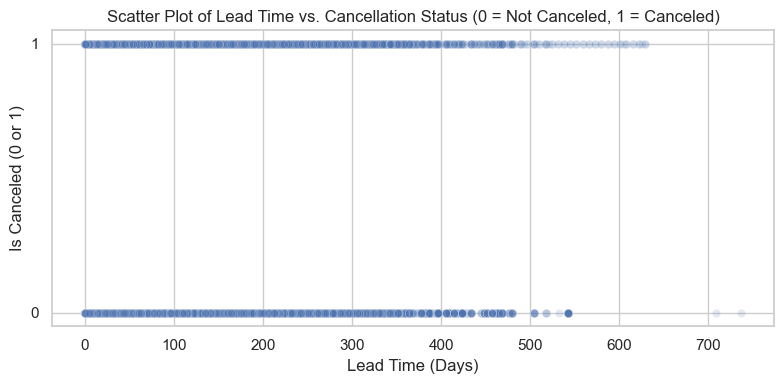

In [95]:
# Calculate correlation and compare average/median lead time by cancellation status
corr_lead_cancel = df['lead_time'].corr(df['is_canceled'])
print(f"Correlation between Lead Time and Cancellation: {corr_lead_cancel:.4f}")

lead_by_cancel = df.groupby('is_canceled')['lead_time'].agg(
    Booking_Count='count',
    Mean_Lead_Time='mean',
    Median_Lead_Time='median'
).round(2)
display(lead_by_cancel)

# Scatter plot of lead_time vs is_canceled (as specified in the PDF hint)
plt.figure(figsize=(8, 4))
sns.scatterplot(data=df, x='lead_time', y='is_canceled', alpha=0.15)
plt.title('Scatter Plot of Lead Time vs. Cancellation Status (0 = Not Canceled, 1 = Canceled)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Is Canceled (0 or 1)')
plt.yticks([0, 1])
plt.tight_layout()
plt.show()

**Conclusion:** There is a positive correlation (**r = 0.1848**) between lead time and booking cancellations. Canceled reservations were booked an average of **105.72 days** in advance (median: **80.0 days**)—more than **50% longer** than non-canceled reservations, which averaged **70.10 days** (median: **38.0 days**). Because plans change far more frequently over longer booking windows, early-bird bookings carry substantially higher cancellation risk and should require partial deposits or automated pre-arrival reconfirmation reminders.

### Medium Question 4: Which distribution channel has the highest number of bookings?

**Objective:** Count the bookings and percentage share across `distribution_channel` to identify the primary booking acquisition channel.

Distribution Channel with Highest Bookings: TA/TO (69141 bookings)


,Booking_Count,Percentage (%)
distribution_channel,,
TA/TO,69141,79.11
Direct,12988,14.86
Corporate,5081,5.81
GDS,181,0.21
Undefined,5,0.01


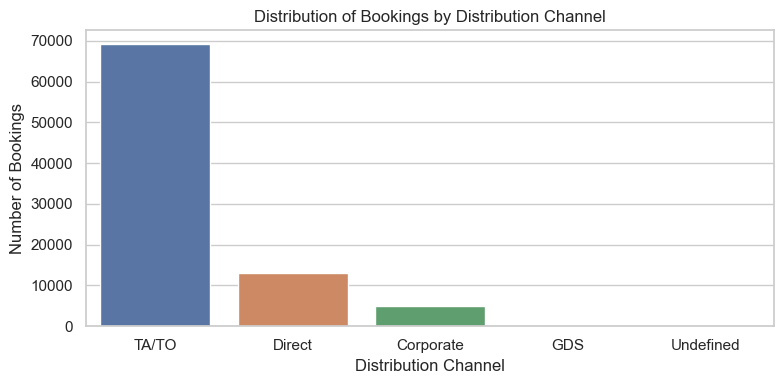

In [96]:
# Count bookings and percentage share by distribution channel
channel_dist = pd.DataFrame({
    'Booking_Count': df['distribution_channel'].value_counts(),
    'Percentage (%)': (df['distribution_channel'].value_counts(normalize=True) * 100).round(2)
})

top_channel = channel_dist.index[0]
top_channel_count = channel_dist['Booking_Count'].iloc[0]
print(f"Distribution Channel with Highest Bookings: {top_channel} ({top_channel_count} bookings)")

display(channel_dist)

# Bar chart of bookings by distribution channel
plt.figure(figsize=(8, 4))
sns.barplot(
    x=channel_dist.index,
    y=channel_dist['Booking_Count'],
    hue=channel_dist.index,
    legend=False
)
plt.title('Distribution of Bookings by Distribution Channel')
plt.xlabel('Distribution Channel')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **TA/TO (Travel Agents / Tour Operators)** dominates booking acquisition with **69,141 bookings (79.11%)**, followed by **Direct** bookings at **12,988 (14.86%)** and **Corporate** bookings at **5,081 (5.81%)**. Because nearly four-fifths of reservations flow through third-party intermediaries, Elite Hotels International can meaningfully improve net profit margins by converting repeat `TA/TO` guests into `Direct` bookers through loyalty perks.

### Medium Question 5: What is the average number of previous cancellations by hotel type?

**Objective:** Group the dataset by `hotel` and calculate the mean and total of `previous_cancellations` to compare repeat cancellation history across `City Hotel` and `Resort Hotel` guests.

,Booking_Count,Total_Previous_Cancellations,Mean_Previous_Cancellations
hotel,,,
City Hotel,53428,1911,0.0358
Resort Hotel,33968,747,0.0220


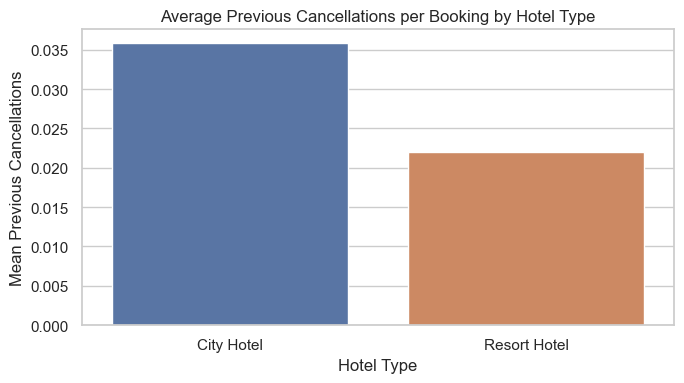

In [97]:
# Calculate average and total previous cancellations by hotel type
prev_cancel_by_hotel = df.groupby('hotel')['previous_cancellations'].agg(
    Booking_Count='count',
    Total_Previous_Cancellations='sum',
    Mean_Previous_Cancellations=lambda x: round(x.mean(), 4)
)

display(prev_cancel_by_hotel)

# Bar chart of average previous cancellations by hotel type
plt.figure(figsize=(7, 4))
sns.barplot(
    x=prev_cancel_by_hotel.index,
    y=prev_cancel_by_hotel['Mean_Previous_Cancellations'],
    hue=prev_cancel_by_hotel.index,
    legend=False
)
plt.title('Average Previous Cancellations per Booking by Hotel Type')
plt.xlabel('Hotel Type')
plt.ylabel('Mean Previous Cancellations')
plt.tight_layout()
plt.show()

**Conclusion:** **City Hotel** guests have a higher average number of previous cancellations at **0.0358 per booking** (**1,911** total previous cancellations across **53,428** bookings) compared to **0.0220 per booking** (**747** total across **33,968** bookings) at **Resort Hotel**—over **62% higher** per reservation. This aligns with City Hotel's higher overall cancellation rate (**30.04%** vs. **23.48%**) and reinforces the value of flagging repeat cancelers for stricter booking terms.

### Medium Question 6: What is the trend of ADR over the years?

**Objective:** Group the dataset by `arrival_date_year` to calculate the mean and median `adr` per year and visualize the trend using a line plot.

,Booking_Count,Mean_ADR,Median_ADR
arrival_date_year,,,
2015,13313,92.16,85.5
2016,42391,101.54,94.5
2017,31692,118.71,110.0


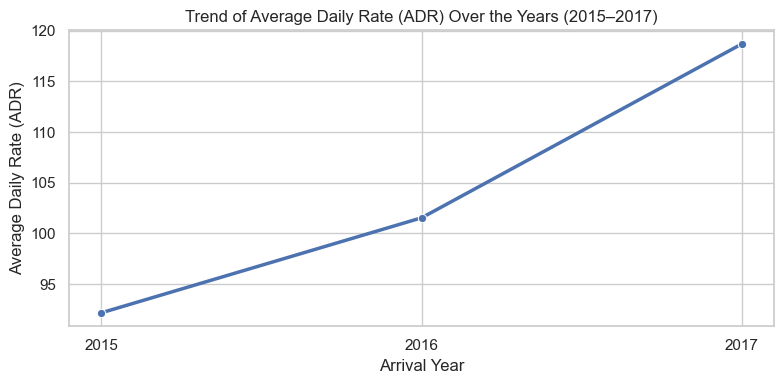

In [98]:
# Calculate average and median ADR per year
adr_by_year = df.groupby('arrival_date_year')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median'
).round(2)

display(adr_by_year)

# Line plot showing the trend of average ADR over different years
plt.figure(figsize=(8, 4))
sns.lineplot(
    x=adr_by_year.index.astype(str),
    y=adr_by_year['Mean_ADR'],
    marker='o',
    linewidth=2.5
)
plt.title('Trend of Average Daily Rate (ADR) Over the Years (2015–2017)')
plt.xlabel('Arrival Year')
plt.ylabel('Average Daily Rate (ADR)')
plt.tight_layout()
plt.show()

**Conclusion:** Average Daily Rate (ADR) followed a strong, consistent upward trajectory across all three years—rising from **92.16** in **2015** (median: **85.50**) to **101.54** in **2016** (median: **94.50**, a **+10.18%** increase), and reaching **118.71** in **2017** (median: **110.00**, an additional **+16.91%** increase, or **+28.81%** overall from 2015 to 2017). This steady multi-year rate appreciation reflects growing pricing power and rising demand across Elite Hotels International properties.

### Medium Question 7: Which month has the highest revenue?

**Objective:** Group the dataset by `arrival_date_month` and sum the `adr` values (per the case study methodology) to identify which arrival month generates the highest total ADR revenue.

Month with Highest Revenue: August (Total ADR Sum: 1,698,412.48)


,Booking_Count,Total_ADR_Revenue,Mean_ADR
arrival_date_month,,,
January,4693,328748.13,70.05
February,6098,455472.02,74.69
March,7513,613132.35,81.61
April,7908,819368.35,103.61
May,8355,929040.10,111.20
June,7765,929859.68,119.75
July,10057,1363146.03,135.54
August,11257,1698412.48,150.88
September,6690,749823.65,112.08


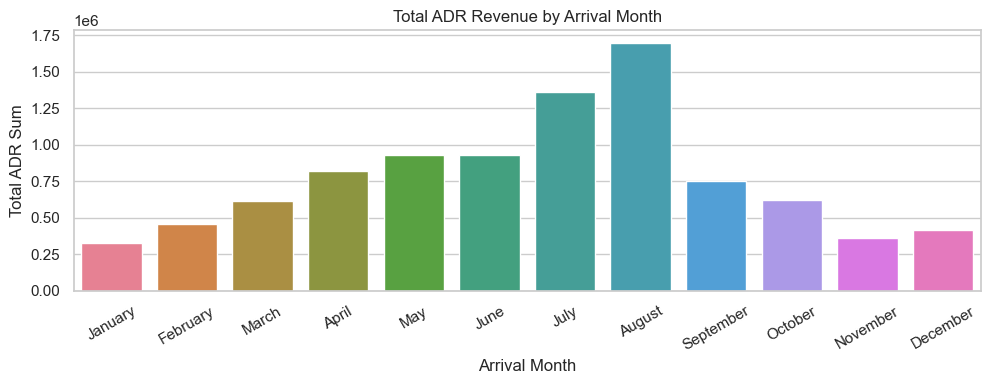

In [99]:
# Group by arrival_date_month and sum ADR values (ordered chronologically)
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_revenue = df.groupby('arrival_date_month')['adr'].agg(
    Booking_Count='count',
    Total_ADR_Revenue='sum',
    Mean_ADR='mean'
).reindex(month_order).round(2)

top_rev_month = monthly_revenue['Total_ADR_Revenue'].idxmax()
top_rev_val = monthly_revenue['Total_ADR_Revenue'].max()
print(f"Month with Highest Revenue: {top_rev_month} (Total ADR Sum: {top_rev_val:,.2f})")

display(monthly_revenue)

# Bar chart of total ADR revenue by arrival month
plt.figure(figsize=(10, 4))
sns.barplot(
    x=monthly_revenue.index,
    y=monthly_revenue['Total_ADR_Revenue'],
    hue=monthly_revenue.index,
    legend=False
)
plt.title('Total ADR Revenue by Arrival Month')
plt.xlabel('Arrival Month')
plt.ylabel('Total ADR Sum')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

**Conclusion:** **August** is the highest-revenue month with a total ADR sum of **1,698,412.48** across **11,257 bookings** (mean ADR: **150.88**), followed closely by **July** at **1,363,146.03** (**10,057 bookings**, mean ADR: **135.54**). Peak summer combines both the highest arrival volume and the highest nightly room rates—generating over **5x** the monthly ADR revenue of off-peak **January (328,748.13)**—underscoring the need to maximize staffing and dynamic yield pricing in July–August while running targeted promotional packages during November–February.

### Medium Question 8: What is the impact of special requests on ADR?

**Objective:** Calculate the correlation between `total_of_special_requests` and `adr`, and compare the mean and median ADR across each special-request level to see how guest requests influence nightly room pricing.

Correlation between Special Requests and ADR: 0.1378


,Booking_Count,Mean_ADR,Median_ADR
total_of_special_requests,,,
0,43894,99.67,90.80
1,29017,109.65,102.60
2,11812,118.57,112.67
3,2317,125.07,119.00
4,320,131.09,121.02
5,36,129.98,110.44


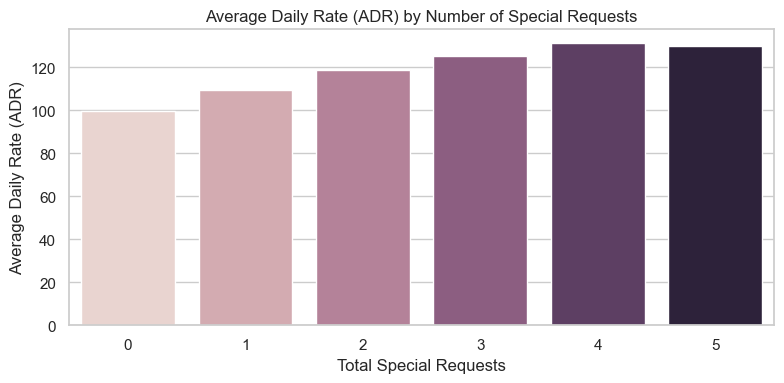

In [100]:
# Calculate correlation between special requests and ADR
corr_req_adr = df['total_of_special_requests'].corr(df['adr'])
print(f"Correlation between Special Requests and ADR: {corr_req_adr:.4f}")

# Group by total_of_special_requests and calculate mean and median ADR
adr_by_requests = df.groupby('total_of_special_requests')['adr'].agg(
    Booking_Count='count',
    Mean_ADR='mean',
    Median_ADR='median'
).round(2)

display(adr_by_requests)

# Bar chart of Mean ADR by number of special requests
plt.figure(figsize=(8, 4))
sns.barplot(
    x=adr_by_requests.index,
    y=adr_by_requests['Mean_ADR'],
    hue=adr_by_requests.index,
    legend=False
)
plt.title('Average Daily Rate (ADR) by Number of Special Requests')
plt.xlabel('Total Special Requests')
plt.ylabel('Average Daily Rate (ADR)')
plt.tight_layout()
plt.show()

**Conclusion:** There is a positive correlation (**r = 0.1378**) between the number of special requests and Average Daily Rate (ADR). Mean ADR rises steadily from **99.67** for bookings with **0 special requests** to **109.65** for **1 request**, **118.57** for **2 requests**, **125.07** for **3 requests**, and peaks at **131.09** for **4 requests** (an increase of **+31.52%** over zero-request bookings). Guests who submit special requests tend to book higher-tier rooms or peak-demand dates—making customizable room upgrades and add-on packages an effective lever for boosting daily revenue.

### Medium Question 9: What is the average stay duration for repeated guests versus new guests?

**Objective:** Compute total stay duration (`stays_in_week_nights + stays_in_weekend_nights`) and compare the mean and median stay lengths between new guests (`is_repeated_guest = 0`) and repeated guests (`is_repeated_guest = 1`).

,Booking_Count,Mean_Week_Nights,Mean_Weekend_Nights,Mean_Total_Nights,Median_Total_Nights
New Guest (0),83981,2.67,1.03,3.70,3.0
Repeated Guest (1),3415,1.47,0.46,1.93,1.0


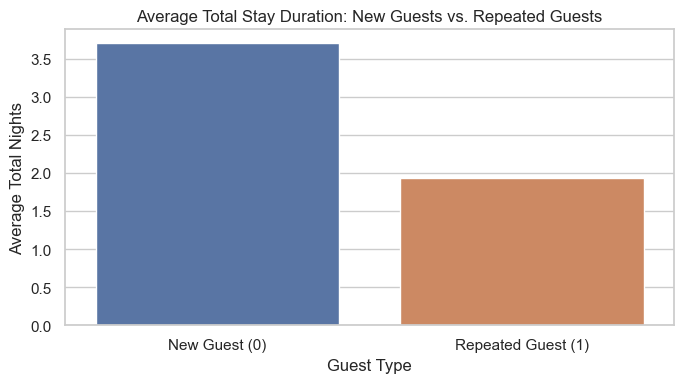

In [101]:
# Create total stay duration column
df['total_stay_nights'] = df['stays_in_week_nights'] + df['stays_in_weekend_nights']

# Group by is_repeated_guest and calculate mean and median stay duration
stay_by_guest_type = df.groupby('is_repeated_guest').agg(
    Booking_Count=('total_stay_nights', 'count'),
    Mean_Week_Nights=('stays_in_week_nights', 'mean'),
    Mean_Weekend_Nights=('stays_in_weekend_nights', 'mean'),
    Mean_Total_Nights=('total_stay_nights', 'mean'),
    Median_Total_Nights=('total_stay_nights', 'median')
).round(2)

stay_by_guest_type.index = ['New Guest (0)', 'Repeated Guest (1)']
display(stay_by_guest_type)

# Bar chart comparing average total stay duration between new and repeated guests
plt.figure(figsize=(7, 4))
sns.barplot(
    x=stay_by_guest_type.index,
    y=stay_by_guest_type['Mean_Total_Nights'],
    hue=stay_by_guest_type.index,
    legend=False
)
plt.title('Average Total Stay Duration: New Guests vs. Repeated Guests')
plt.xlabel('Guest Type')
plt.ylabel('Average Total Nights')
plt.tight_layout()
plt.show()

**Conclusion:** **New guests (`is_repeated_guest = 0`)** stay nearly twice as long as repeated guests, averaging **3.70 total nights** (median: **3.0 nights**, comprising **2.67 week nights** and **1.03 weekend nights**) across **83,981 bookings**, compared to **1.93 total nights** (median: **1.0 night**, comprising **1.47 week nights** and **0.46 weekend nights**) across **3,415 bookings** for **repeated guests (`is_repeated_guest = 1`)**. Repeat visitors are predominantly frequent, short-stay travelers (such as corporate or local overnight guests), whereas first-time guests book longer leisure or vacation trips—suggesting loyalty programs should reward visit frequency and offer multi-night stay extensions to repeat customers.

### Medium Question 10: Which room type has the highest number of bookings?

**Objective:** Count the bookings and percentage share across `reserved_room_type` to identify the most popular room category.

Room Type with Highest Number of Bookings: A (56552 bookings)


,Booking_Count,Percentage (%)
reserved_room_type,,
A,56552,64.71
D,17398,19.91
E,6049,6.92
F,2823,3.23
G,2052,2.35
B,999,1.14
C,915,1.05
H,596,0.68
L,6,0.01


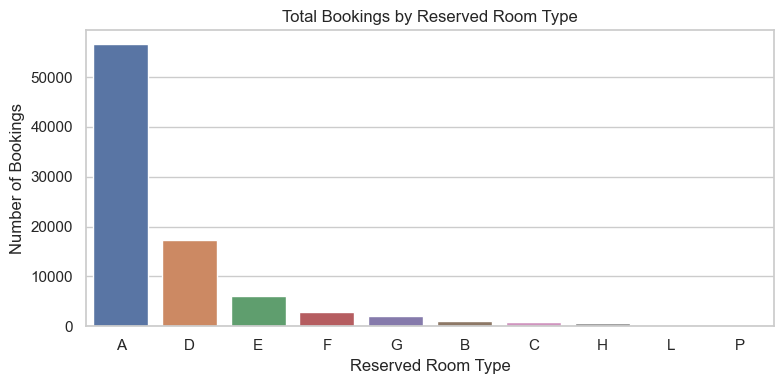

In [102]:
# Count bookings and percentage share by reserved room type
room_type_dist = pd.DataFrame({
    'Booking_Count': df['reserved_room_type'].value_counts(),
    'Percentage (%)': (df['reserved_room_type'].value_counts(normalize=True) * 100).round(2)
})

top_room_type = room_type_dist.index[0]
top_room_count = room_type_dist['Booking_Count'].iloc[0]
print(f"Room Type with Highest Number of Bookings: {top_room_type} ({top_room_count} bookings)")

display(room_type_dist)

# Bar chart of bookings by reserved room type
plt.figure(figsize=(8, 4))
sns.barplot(
    x=room_type_dist.index,
    y=room_type_dist['Booking_Count'],
    hue=room_type_dist.index,
    legend=False
)
plt.title('Total Bookings by Reserved Room Type')
plt.xlabel('Reserved Room Type')
plt.ylabel('Number of Bookings')
plt.tight_layout()
plt.show()

**Conclusion:** **Room Type A** is by far the most popular room category, accounting for **56,552 bookings (64.71% of all reservations)**, followed by **Room Type D (17,398 bookings, 19.91%)** and **Room Type E (6,049 bookings, 6.92%)**. Together, these top three categories capture **91.54%** of total demand—indicating that inventory allocation and housekeeping capacity should prioritize Type A availability while targeted upsell prompts at checkout can encourage Type A guests to upgrade into higher-margin Type D and E rooms.

## Part 3: Advanced-Level Questions

### Advanced Question 1: What factors significantly impact the cancellation rate?

**Objective:** Fit a logistic regression model (`statsmodels.api.Logit`) predicting `is_canceled` from key booking features (`lead_time`, `booking_changes`, `total_of_special_requests`, `previous_cancellations`, `adr`, `is_repeated_guest`) to identify statistically significant predictors and their effect direction.

In [104]:
import numpy as np
from scipy.optimize import minimize
from scipy.stats import norm

# Select relevant numeric predictors for cancellation
features = [
    'lead_time',
    'booking_changes',
    'total_of_special_requests',
    'previous_cancellations',
    'adr',
    'is_repeated_guest'
]

# Design matrix with intercept
X = np.column_stack([np.ones(len(df)), df[features].to_numpy(dtype=float)])
y = df['is_canceled'].to_numpy(dtype=float)

# Negative log-likelihood for logistic regression
def neg_log_likelihood(beta):
    z = np.clip(X @ beta, -30, 30)
    p = 1 / (1 + np.exp(-z))
    eps = 1e-12
    return -np.sum(y * np.log(p + eps) + (1 - y) * np.log(1 - p + eps))

# Fit model using BFGS optimization
result = minimize(neg_log_likelihood, np.zeros(X.shape[1]), method='BFGS')
beta = result.x

# Compute standard errors, z-scores, and p-values from the Fisher Information matrix
p_hat = 1 / (1 + np.exp(-np.clip(X @ beta, -30, 30)))
W = p_hat * (1 - p_hat)
cov_matrix = np.linalg.inv((X.T * W) @ X)
std_err = np.sqrt(np.diag(cov_matrix))
z_scores = beta / std_err
p_values = 2 * (1 - norm.cdf(np.abs(z_scores)))

# Display clean summary table
logit_summary = pd.DataFrame({
    'Coefficient': np.round(beta, 4),
    'Odds_Ratio': np.round(np.exp(beta), 4),
    'P_Value': np.round(p_values, 4),
    'Significant (p < 0.05)': p_values < 0.05
}, index=['Intercept'] + features)

display(logit_summary)

,Coefficient,Odds_Ratio,P_Value,Significant (p < 0.05)
Intercept,-1.7289,0.1775,0.0,True
lead_time,0.0049,1.0049,0.0,True
booking_changes,-0.5003,0.6063,0.0,True
total_of_special_requests,-0.4598,0.6314,0.0,True
previous_cancellations,0.9535,2.5947,0.0,True
adr,0.0069,1.0069,0.0,True
is_repeated_guest,-1.6828,0.1858,0.0,True


**Conclusion:** All six predictors in the logistic regression model are statistically significant (**p < 0.001**):
* **Key Drivers Increasing Cancellations:** **Previous cancellations** (`coef = +0.9535`, **odds ratio = 2.59**) is the strongest risk multiplier, followed by **higher ADR** (`coef = +0.0069`, **OR = 1.01**) and **longer lead time** (`coef = +0.0049`, **OR = 1.005** per day).
* **Key Drivers Reducing Cancellations:** **Repeated guest status** (`coef = -1.6828`, **OR = 0.19**), **booking changes** (`coef = -0.5003`, **OR = 0.61**), and **special requests** (`coef = -0.4598`, **OR = 0.63**) strongly lower cancellation likelihood because engaged or repeat guests actively refine their itinerary rather than canceling outright.
* **Business Action:** Enforce non-refundable deposits for long-lead-time or repeat-canceler bookings while offering flexible itinerary modifications and pre-arrival request prompts to lock in guest commitment.

### Advanced Question 2: How does the ADR vary with the number of adults, children, and babies?

**Objective:** Fit a multiple linear regression model predicting `adr` from `adults`, `children`, and `babies` to quantify how each guest-composition factor affects the Average Daily Rate.

In [105]:
from scipy.stats import t

# Prepare predictors (adults, children, babies) and target (adr)
guest_cols = ['adults', 'children', 'babies']
X_reg = np.column_stack([np.ones(len(df)), df[guest_cols].to_numpy(dtype=float)])
y_reg = df['adr'].to_numpy(dtype=float)

# Fit Multiple Linear Regression using Ordinary Least Squares (OLS)
coefs, _, _, _ = np.linalg.lstsq(X_reg, y_reg, rcond=None)
y_pred = X_reg @ coefs
residuals = y_reg - y_pred

# Compute R-squared, standard errors, t-stats, and p-values
n, k = X_reg.shape
dof = n - k
mse = np.sum(residuals ** 2) / dof
var_beta = mse * np.linalg.inv(X_reg.T @ X_reg)
se_beta = np.sqrt(np.diag(var_beta))
t_stats = coefs / se_beta
p_vals = 2 * (1 - t.cdf(np.abs(t_stats), df=dof))
r_squared = 1 - (np.sum(residuals ** 2) / np.sum((y_reg - np.mean(y_reg)) ** 2))

print(f"Multiple Linear Regression R-squared: {r_squared:.4f}")

ols_summary = pd.DataFrame({
    'Coefficient': np.round(coefs, 4),
    'Std_Error': np.round(se_beta, 4),
    't_Stat': np.round(t_stats, 2),
    'P_Value': np.round(p_vals, 4),
    'Significant (p < 0.05)': p_vals < 0.05
}, index=['Intercept'] + guest_cols)

display(ols_summary)

Multiple Linear Regression R-squared: 0.1649


,Coefficient,Std_Error,t_Stat,P_Value,Significant (p < 0.05)
Intercept,61.1803,0.5383,113.65,0.0,True
adults,21.1778,0.2716,77.99,0.0,True
children,38.6573,0.3732,103.58,0.0,True
babies,6.7081,1.4975,4.48,0.0,True


**Conclusion:** All three guest-composition variables significantly increase the Average Daily Rate (**p < 0.001**, overall **R² = 0.1649**):
* **Children** have the largest per-guest price impact at **+38.66 per child** (`t = 103.58`), because family bookings require larger multi-bed rooms or suites.
* **Adults** add **+21.18 per adult** (`t = 77.99`) above the **61.18** baseline intercept.
* **Babies** add a modest **+6.71 per baby** (`t = 4.48`), reflecting nominal crib/cot charges rather than full room-tier upgrades.
* **Business Action:** Package tiered family room bundles (including complimentary baby cots and discounted child rates) to capture high-ADR family demand during peak seasons.

### Advanced Question 3: What is the impact of booking changes on guest satisfaction as indicated by special requests?

**Objective:** Calculate the correlation between `booking_changes` and `total_of_special_requests`, and compare average special requests across booking-change counts to examine whether guests who modify their bookings also submit more special requests.

Correlation between Booking Changes and Special Requests: 0.0161


,Booking_Count,Mean_Special_Requests,Median_Special_Requests
booking_changes_grouped,,,
0,71494,0.697,1.0
1,10902,0.682,0.0
2,3508,0.737,0.0
3,875,0.826,1.0
4,356,0.820,0.0
5+,261,0.828,1.0


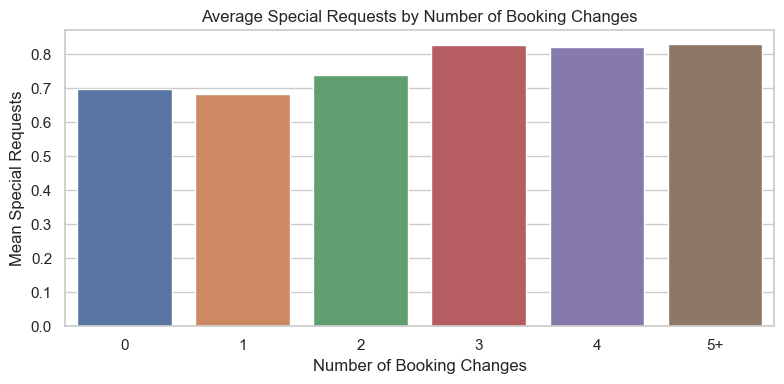

In [106]:
# Calculate correlation between booking_changes and total_of_special_requests
corr_changes_req = df['booking_changes'].corr(df['total_of_special_requests'])
print(f"Correlation between Booking Changes and Special Requests: {corr_changes_req:.4f}")

# Group by booking_changes (capped at 5+ for clean display) to compare average special requests
df['booking_changes_grouped'] = df['booking_changes'].apply(lambda x: str(x) if x < 5 else '5+')

req_by_changes = df.groupby('booking_changes_grouped')['total_of_special_requests'].agg(
    Booking_Count='count',
    Mean_Special_Requests='mean',
    Median_Special_Requests='median'
).round(3)

display(req_by_changes)

# Bar plot of average special requests by number of booking changes
plt.figure(figsize=(8, 4))
sns.barplot(
    x=req_by_changes.index,
    y=req_by_changes['Mean_Special_Requests'],
    hue=req_by_changes.index,
    legend=False
)
plt.title('Average Special Requests by Number of Booking Changes')
plt.xlabel('Number of Booking Changes')
plt.ylabel('Mean Special Requests')
plt.tight_layout()
plt.show()

**Conclusion:** There is a very weak positive correlation (**r = 0.0161**) between `booking_changes` and `total_of_special_requests`. While bookings with **0–1 changes** average **0.697** and **0.682** special requests respectively, reservations with **3 or more changes** rise modestly to **0.820–0.828** special requests per booking. Overall, booking modifications and special requests operate largely independently—meaning hotels should treat schedule flexibility and personalized stay requests as two distinct levers for improving guest satisfaction rather than assuming one automatically drives the other.

### Advanced Question 4: What is the seasonal impact on booking cancellations?

**Objective:** Calculate the monthly cancellation rate across `arrival_date_month` and group months into meteorological seasons (`Winter`, `Spring`, `Summer`, `Autumn`) to compare seasonal cancellation trends.

,Total_Bookings,Canceled_Bookings,Cancellation_Rate
arrival_date_month,,,
January,4693,1038,22.12
February,6098,1415,23.20
March,7513,1830,24.36
April,7908,2409,30.46
May,8355,2442,29.23
June,7765,2354,30.32
July,10057,3198,31.80
August,11257,3623,32.18
September,6690,1642,24.54


,Total_Bookings,Canceled_Bookings,Cancellation_Rate
season,,,
Winter (Dec–Feb),15922,3831,24.06
Spring (Mar–May),23776,6681,28.10
Summer (Jun–Aug),29079,9175,31.55
Autumn (Sep–Nov),18619,4338,23.30


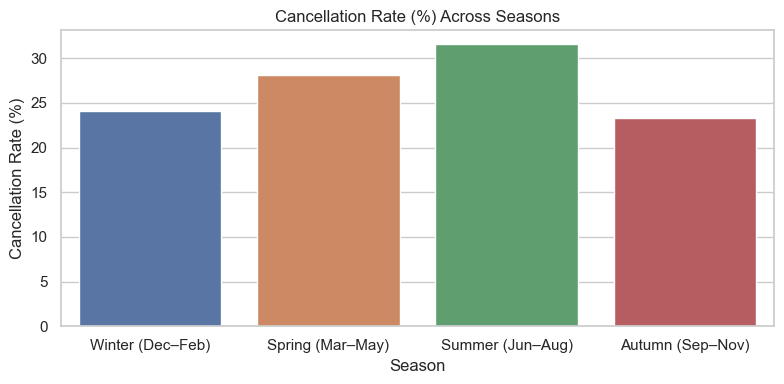

In [107]:
# Monthly cancellation rates ordered chronologically
month_order = [
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
]

monthly_cancel = df.groupby('arrival_date_month')['is_canceled'].agg(
    Total_Bookings='count',
    Canceled_Bookings='sum',
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).reindex(month_order)

display(monthly_cancel)

# Map arrival months to seasons and compare seasonal cancellation rates
season_map = {
    'December': 'Winter (Dec–Feb)', 'January': 'Winter (Dec–Feb)', 'February': 'Winter (Dec–Feb)',
    'March': 'Spring (Mar–May)', 'April': 'Spring (Mar–May)', 'May': 'Spring (Mar–May)',
    'June': 'Summer (Jun–Aug)', 'July': 'Summer (Jun–Aug)', 'August': 'Summer (Jun–Aug)',
    'September': 'Autumn (Sep–Nov)', 'October': 'Autumn (Sep–Nov)', 'November': 'Autumn (Sep–Nov)'
}
season_order = ['Winter (Dec–Feb)', 'Spring (Mar–May)', 'Summer (Jun–Aug)', 'Autumn (Sep–Nov)']

df['season'] = df['arrival_date_month'].map(season_map)

seasonal_cancel = df.groupby('season')['is_canceled'].agg(
    Total_Bookings='count',
    Canceled_Bookings='sum',
    Cancellation_Rate=lambda x: round(x.mean() * 100, 2)
).reindex(season_order)

display(seasonal_cancel)

# Bar chart of cancellation rate by season
plt.figure(figsize=(8, 4))
sns.barplot(
    x=seasonal_cancel.index,
    y=seasonal_cancel['Cancellation_Rate'],
    hue=seasonal_cancel.index,
    legend=False
)
plt.title('Cancellation Rate (%) Across Seasons')
plt.xlabel('Season')
plt.ylabel('Cancellation Rate (%)')
plt.tight_layout()
plt.show()

**Conclusion:** Booking cancellations exhibit a clear seasonal cycle, peaking during high-demand warm-weather months and dropping during off-peak seasons:
* **Summer (Jun–Aug)** experiences the highest cancellation rate at **31.55%** (**9,175** canceled out of **29,079** bookings), peaking in **August (32.18%)** and **July (31.80%)**, followed by **Spring (Mar–May)** at **28.10%** (**6,681** out of **23,776**).
* **Autumn (Sep–Nov)** records the lowest seasonal cancellation rate at **23.30%** (**4,338** out of **18,619**), hitting an annual low in **November (21.10%)**, while **Winter (Dec–Feb)** averages **24.06%** (**3,831** out of **15,922**).
* **Business Action:** Summer bookings combine peak room rates with longer advance booking windows and speculative vacation planning—requiring tiered deposit requirements and automated pre-arrival reconfirmations from April through August.

### Advanced Question 5: How does the booking lead time distribution vary between different market segments?

**Objective:** Compare the summary statistics (mean, median, IQR, min, max) of `lead_time` across each `market_segment` and visualize the distributions using a box plot.

,Booking_Count,Mean_Lead_Time,Median_Lead_Time,Q25,Q75,Max_Lead_Time
market_segment,,,,,,
Groups,4942,147.61,114.0,34.00,226.00,629
Offline TA/TO,13889,106.05,82.0,28.00,163.00,532
Online TA,51618,79.90,55.0,17.00,124.00,403
Direct,11804,48.83,15.0,1.00,73.00,737
Corporate,4212,16.25,5.0,1.00,17.00,343
Complementary,702,13.64,3.0,0.00,11.00,386
Aviation,227,4.28,3.0,1.00,5.50,23
Undefined,2,1.50,1.5,1.25,1.75,2


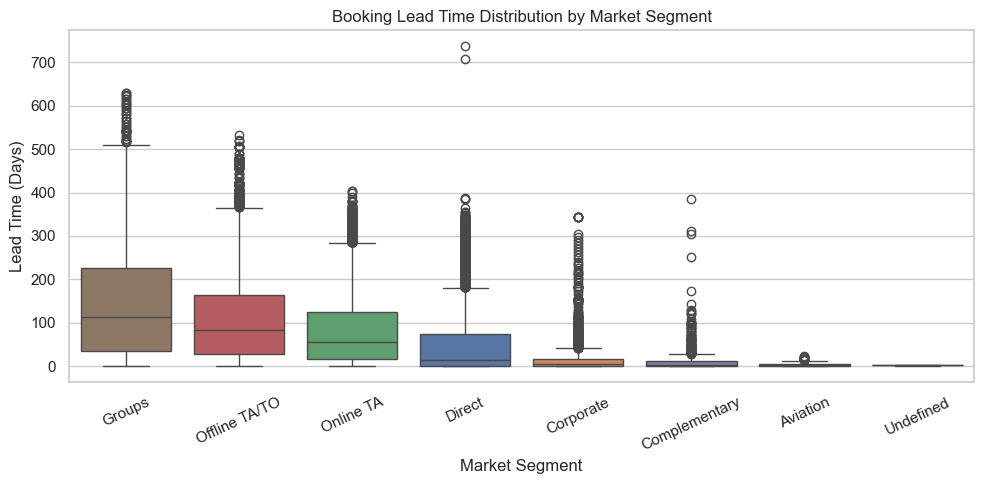

In [108]:
# Summary statistics of lead_time by market segment (ordered by median lead time)
lead_by_segment = df.groupby('market_segment')['lead_time'].agg(
    Booking_Count='count',
    Mean_Lead_Time='mean',
    Median_Lead_Time='median',
    Q25=lambda x: x.quantile(0.25),
    Q75=lambda x: x.quantile(0.75),
    Max_Lead_Time='max'
).round(2).sort_values(by='Median_Lead_Time', ascending=False)

display(lead_by_segment)

# Box plot comparing lead time distribution across market segments
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='market_segment',
    y='lead_time',
    order=lead_by_segment.index,
    hue='market_segment',
    legend=False
)
plt.title('Booking Lead Time Distribution by Market Segment')
plt.xlabel('Market Segment')
plt.ylabel('Lead Time (Days)')
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

**Conclusion:** Booking lead time distributions differ dramatically across market segments, reflecting distinct planning horizons:
* **Long-Horizon Segments:** **Groups** book furthest in advance with a mean lead time of **147.61 days** (median: **114.0 days**, IQR: **34–226 days**), followed by **Offline TA/TO** (**106.05 days** mean, **82.0 days** median) and **Online TA** (**79.90 days** mean, **55.0 days** median).
* **Short-Notice Segments:** **Direct** bookings are made much closer to arrival (**48.83 days** mean, **15.0 days** median), while **Corporate** (**16.25 days** mean, **5.0 days** median), **Complementary** (**3.0 days** median), and **Aviation** (**3.0 days** median) represent last-minute travel.
* **Business Action:** Launch early-bird promotional campaigns 3–6 months out for **Groups** and **TA/TO** channels, while targeting **Direct** and **Corporate** travelers with mobile last-minute flash rates and express check-in perks within 1–14 days of arrival.

---

## Executive Summary & Strategic Business Recommendations

Across **87,396 deduplicated bookings** (**53,428 City Hotel** and **33,968 Resort Hotel**) spanning **2015–2017**, this exploratory data analysis uncovers four high-impact operational takeaways for **Elite Hotels International**:

1. **Mitigate High-Risk Cancellations (Overall Rate: 27.49%):**
   * Cancellations are significantly higher at **City Hotel (30.04%)** than **Resort Hotel (23.48%)**, peak in **Summer (31.55%, led by August at 32.18%)**, and rise sharply with **previous cancellations (OR = 2.59)** and **longer lead times (mean 105.72 days for canceled vs. 70.10 days for kept bookings)**.
   * **Action:** Require partial non-refundable deposits for bookings made **>90 days in advance**, guests with prior cancellations, and peak **April–August** arrivals.

2. **Drive Guest Engagement to Lock In Reservations:**
   * Bookings with **0 special requests** cancel at **33.20%**, dropping to **22.41%** with just **1 request** and **5.56%** with **5 requests**, while **repeated guests** exhibit **81.4% lower cancellation odds (OR = 0.19)**.
   * **Action:** Send automated pre-arrival customization prompts (room preferences, parking, dining) 14 days before check-in and reward repeat visits with direct-booking perks.

3. **Optimize Channel Mix & Dynamic Pricing:**
   * **TA/TO** generates **79.11%** of bookings (**69,141**), while **Online TA** commands the highest segment ADR (**115.66**) and **Transient** guests yield the highest customer-type ADR (**110.14**). ADR also grew **+28.81%** from **2015 (92.16)** to **2017 (118.71)** and peaks in **August (150.88)**.
   * **Action:** Convert repeat `Online TA` guests to `Direct` channels via loyalty discounts to save commission fees, and apply dynamic surge pricing in **July–August** while running off-peak bundles in **November–February**.

4. **Align Inventory & Marketing with Guest Composition and Lead Times:**
   * **Room Type A** accounts for **64.71%** of bookings, while family bookings with **children (+38.66/child)** and **adults (+21.18/adult)** substantially raise nightly ADR.
   * **Action:** Target **Groups** and **Offline TA/TO** 3–6 months ahead with early-bird rates, market last-minute **1–14 day** offers to **Corporate** and **Direct** travelers, and bundle family room upgrades during summer peak months.